# Progetto di Machine Learning

In questo progetto analizzerò le performance dei modelli studiati a lezione sul dataset *Wine*, importato da scikit-learn.
Ho diviso il progetto nelle seguenti fasi:
- Analisi Esplorativa dei Dati
- Split e Varianza Spiegata
- CV, PCA e Valutazione Iniziale
- Ottimizzazione Iperparametri
- Valutazione Finale

## Fase 1: Analisi Esplorativa dei Dati

Caricamento librerie, dataset e correlazione tra feature

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, f1_score
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from xgboost import XGBClassifier

Dimensioni dataset: (178, 13)
Classi target: ['class_0' 'class_1' 'class_2']
Distribuzione classi: [59 71 48]


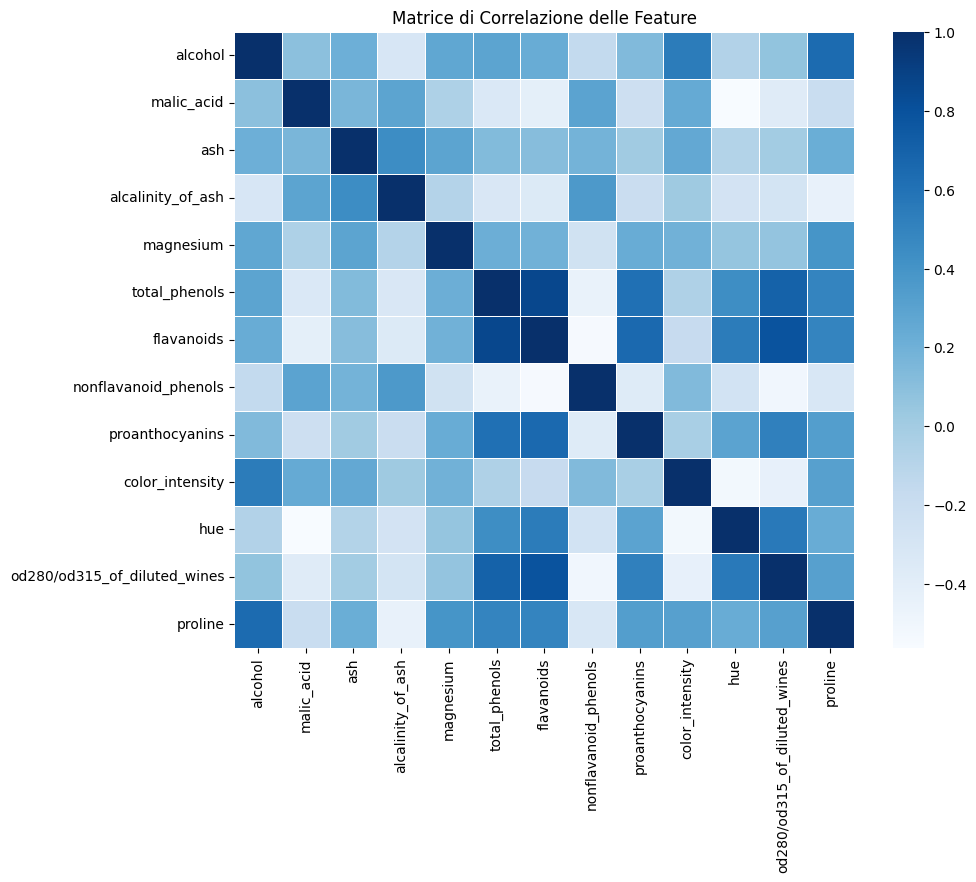

In [2]:
wine = load_wine()
X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = wine.target

print(f"Dimensioni dataset: {X.shape}")
print(f"Classi target: {wine.target_names}")
print(f"Distribuzione classi: {np.bincount(y)}")


# Matrice di correlazione
plt.figure(figsize=(10, 8))
sns.heatmap(X.corr(), annot=False, cmap='Blues', linewidths=0.5)
plt.title("Matrice di Correlazione delle Feature")
plt.show()

## Fase 2: Split e Varianza Spiegata

Utilizzo i modelli visti a lezione e applico la PCA solo ai modelli sensibili alla multicollinearità (di conseguenza escludo i metodi tree-based)

**Modelli Parametrici:**
- Regressione Logistica (Multinomiale)
- LDA
- QDA
- Gaussian Naive Bayes

**Modelli Non Parametrici:**
- kNN
- SVM
- Decision Tree

**Modelli Ensemble**
- Bagging
- Random Forest
- AdaBoost
- Gradient Boosting
- XGBoost

Componenti necessarie per spiegare il 95% della varianza: 10
Varianza spiegata dai primi 10 componenti: 96.50%


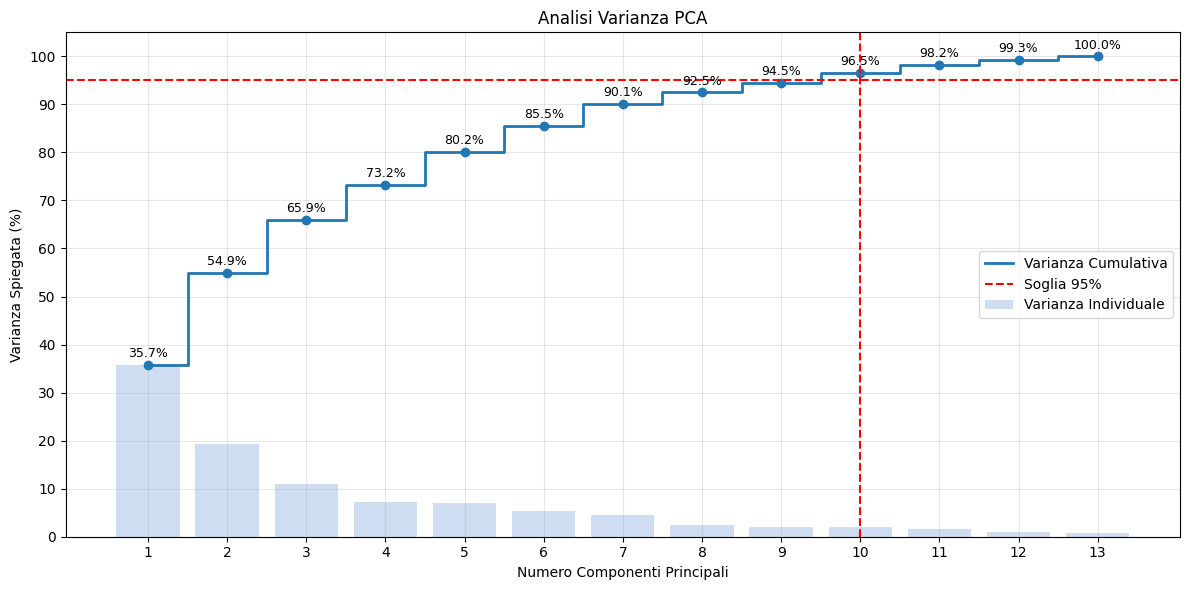

In [3]:
# Split del dataset: 70% Training, 30% Test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)


# I modelli lineari e geometrici hanno bisogno della PCA
modelli_pca = {
    "Regressione Logistica": LogisticRegression(max_iter=1000, random_state=42),
    "LDA": LinearDiscriminantAnalysis(),
    "QDA": QuadraticDiscriminantAnalysis(),
    "Gaussian Naive Bayes": GaussianNB(),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(probability=True, random_state=42)
}


# I modelli tree-based non hanno bisogno della PCA
modelli_no_pca = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Bagging": BaggingClassifier(n_estimators=50, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "AdaBoost": AdaBoostClassifier(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
}


# Analisi della varianza spiegata con PCA
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)


# Applico PCA senza limiti per vedere tutti i componenti
pca = PCA(n_components=None)
pca.fit(X_train_scaled)

exp_var = pca.explained_variance_ratio_ * 100
cum_var = np.cumsum(exp_var)
n_95 = np.argmax(cum_var >= 95) + 1


# Visualizzazione varianza spiegata
print(f"Componenti necessarie per spiegare il 95% della varianza: {n_95}\nVarianza spiegata dai primi {n_95} componenti: {cum_var[n_95-1]:.2f}%")
plt.figure(figsize=(12, 6))
x_axis = range(1, len(exp_var) + 1)
plt.bar(x_axis, exp_var, alpha=0.6, label='Varianza Individuale', color='#aec7e8')
plt.step(x_axis, cum_var, where='mid', label='Varianza Cumulativa', color='#1f77b4', linewidth=2)
plt.plot(x_axis, cum_var, 'o', color='#1f77b4')
plt.axhline(y=95, color='r', linestyle='--', label='Soglia 95%')
plt.axvline(x=n_95, color='r', linestyle='--')
plt.title(f'Analisi Varianza PCA')
plt.ylabel('Varianza Spiegata (%)')
plt.xlabel('Numero Componenti Principali')
plt.xticks(x_axis)
plt.yticks(np.arange(0, 101, 10))
plt.legend(loc='center right')
plt.grid(True, alpha=0.3)

for i, v in enumerate(cum_var):
    plt.text(i+1, v+1, f'{v:.1f}%', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

## Fase 3: CV, PCA e Valutazione Iniziale

Confronto iniziale dei modelli con e senza PCA. Ho utilizzato le pipeline per semplicità del codice.


Valutazione iniziale: 5-fold cross-validation sul training set

              Modello  Accuracy       F1
                  LDA  0.984000 0.983410
                  SVM  0.984000 0.984444
 Gaussian Naive Bayes  0.983667 0.984428
                  QDA  0.983667 0.982812
Regressione Logistica  0.976000 0.976002
        Random Forest  0.976000 0.976002
              XGBoost  0.968000 0.967700
                  KNN  0.968000 0.969811
              Bagging  0.959667 0.958269
             AdaBoost  0.944000 0.943860
    Gradient Boosting  0.895000 0.888970
        Decision Tree  0.878333 0.877135


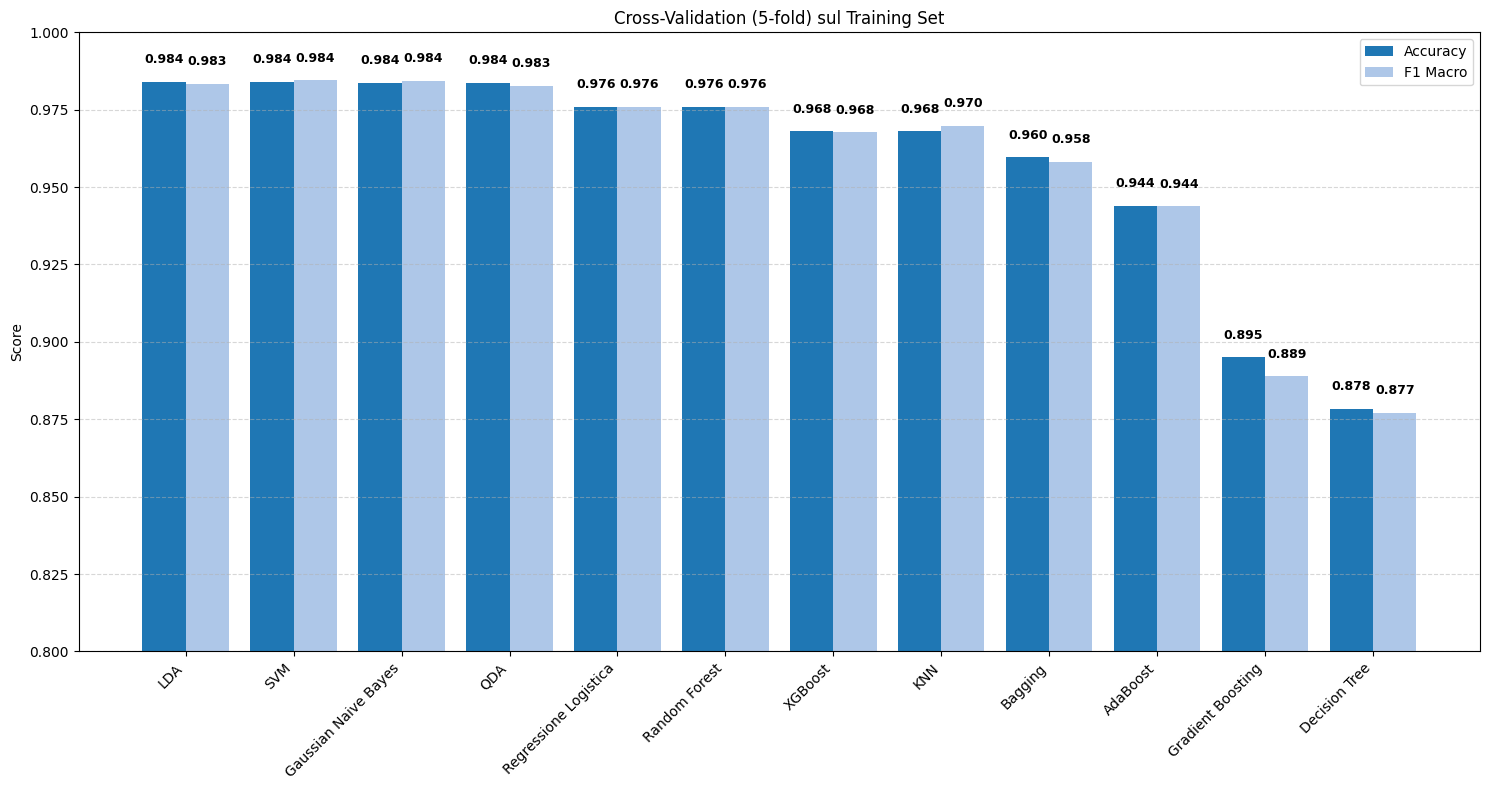

In [4]:
risultati = []
n_splits = 5
kfold = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
metriche = {'acc': 'accuracy', 'f1': 'f1_macro'}


# Ciclo modelli PCA
for name, model in modelli_pca.items():
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('pca', PCA(n_components=0.95, random_state=42)),
        ('clf', model)
    ])
    scores = cross_validate(pipe, X_train, y_train, cv=kfold, scoring=metriche)
    risultati.append({'Modello': name, 'Accuracy': scores['test_acc'].mean(), 'F1': scores['test_f1'].mean()})


# Ciclo modelli no PCA
for name, model in modelli_no_pca.items():
    scores = cross_validate(model, X_train, y_train, cv=kfold, scoring=metriche)
    risultati.append({'Modello': name, 'Accuracy': scores['test_acc'].mean(), 'F1': scores['test_f1'].mean()})


# Visualizzazione risultati iniziali
df_plot = pd.DataFrame(risultati).sort_values(by='Accuracy', ascending=False)
print("Valutazione iniziale: 5-fold cross-validation sul training set\n")
print(df_plot.to_string(index=False))

plt.figure(figsize=(15, 8))
x = np.arange(len(df_plot['Modello']))
width = 0.4

bars1 = plt.bar(x - width/2, df_plot['Accuracy'], width, label='Accuracy', color='#1f77b4')
bars2 = plt.bar(x + width/2, df_plot['F1'], width, label='F1 Macro', color='#aec7e8')

plt.title('Cross-Validation (5-fold) sul Training Set')
plt.ylabel('Score')
plt.xticks(x, df_plot['Modello'], rotation=45, ha='right')
plt.ylim(0.8, 1.0)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)

def labels(bars):
    for bar in bars:
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, height + 0.005, f'{height:.3f}',
                 ha='center', va='bottom', rotation=0, fontsize=9, fontweight='bold')

labels(bars1)
labels(bars2)

plt.tight_layout()
plt.show()

## Fase 4: Ottimizzazione Iperparametri

Ricerca dei migliori iperparametri (tramite _GridSearchCV_), di:
- Decision Tree
    - alpha
- KNN
    - k
- SVM
    - C
    - gamma
    - kernel

In [5]:
# Decision Tree: ricerca del miglior alpha
dt_temp = DecisionTreeClassifier(random_state=42)
path = dt_temp.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas = path.ccp_alphas[:-1]

pipe_dt = Pipeline([('dt', DecisionTreeClassifier(random_state=42))])
grid_dt = GridSearchCV(
    pipe_dt,
    param_grid={'dt__ccp_alpha': ccp_alphas},
    cv=kfold,
    scoring='accuracy'
)
grid_dt.fit(X_train, y_train)
print(f"\nDecision Tree\n- Miglior alpha: {grid_dt.best_params_['dt__ccp_alpha']:.5f}")
print(f"- Score: {grid_dt.best_score_:.4f}")


# KNN: ricerca del miglior K
pipe_knn = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=0.95, random_state=42)),
    ('knn', KNeighborsClassifier())
])
grid_knn = GridSearchCV(
    pipe_knn,
    param_grid={'knn__n_neighbors': range(1, 21)},
    cv=kfold,
    scoring='accuracy'
)
grid_knn.fit(X_train, y_train)
print(f"\nKNN\n- Miglior K: {grid_knn.best_params_['knn__n_neighbors']}")
print(f"- Score: {grid_knn.best_score_:.4f}")


# SVM: ricerca dei migliori C, gamma e kernel
pipe_svm = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=0.95, random_state=42)),
    ('svm', SVC(probability=True, random_state=42))
])

param_grid_svm = [
    {
        'svm__kernel': ['linear'],       # gamma è inutile per kernel lineare
        'svm__C': [0.1, 1, 10, 100]
    },
    {
        'svm__kernel': ['rbf', 'poly'],         # limite decisionale di confine tra le classi
        'svm__C': [0.1, 1, 10, 100],            # tolleranza agli errori
        'svm__gamma': [0.001, 0.01, 0.1, 1, 10] # raggio d'influenza di ogni singolo punto
    }
]

grid_svm = GridSearchCV(pipe_svm, param_grid_svm, cv=kfold, scoring='accuracy')
grid_svm.fit(X_train, y_train)
print(f"\nSVM\n- Miglior kernel: {grid_svm.best_params_['svm__kernel']}\n- Miglior C: {grid_svm.best_params_['svm__C']}\n- Miglior gamma: {grid_svm.best_params_.get('svm__gamma', 'N/A')}")
print(f"- Score: {grid_svm.best_score_:.4f}")

best_dt = grid_dt.best_estimator_
best_knn = grid_knn.best_estimator_
best_svm = grid_svm.best_estimator_


Decision Tree
- Miglior alpha: 0.01382
- Score: 0.8950

KNN
- Miglior K: 13
- Score: 0.9760

SVM
- Miglior kernel: rbf
- Miglior C: 10
- Miglior gamma: 0.01
- Score: 0.9920


## Fase 5: Valutazione Finale

Confronto finale dei modelli studiati

Valutazione finale sul test set

              Modello  Accuracy       F1
        Random Forest  1.000000 1.000000
              XGBoost  1.000000 1.000000
              Bagging  1.000000 1.000000
                  QDA  1.000000 1.000000
             AdaBoost  0.981481 0.981117
 Gaussian Naive Bayes  0.981481 0.980754
          SVM (Tuned)  0.981481 0.982861
Regressione Logistica  0.981481 0.982861
                  LDA  0.962963 0.963572
Decision Tree (Tuned)  0.962963 0.963830
    Gradient Boosting  0.962963 0.965241
          KNN (Tuned)  0.944444 0.944517


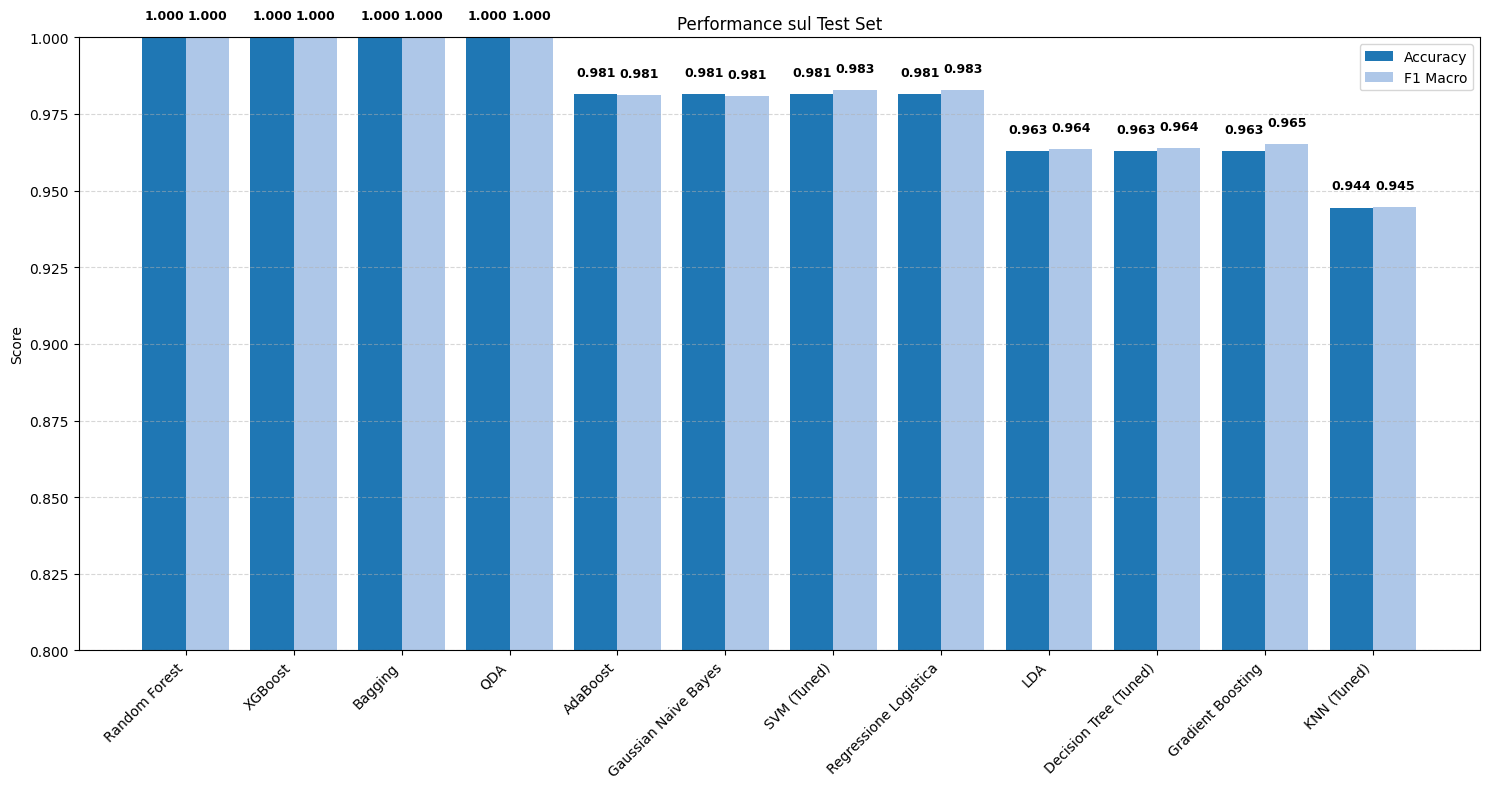

In [6]:
modelli_finali = {}

modelli_finali["Decision Tree (Tuned)"] = grid_dt.best_estimator_
modelli_finali["KNN (Tuned)"] = grid_knn.best_estimator_
modelli_finali["SVM (Tuned)"] = grid_svm.best_estimator_

for name, model in modelli_pca.items():
    if name not in ["Decision Tree", "KNN", "SVM"]:
        modelli_finali[name] = Pipeline([
            ('scaler', StandardScaler()),
            ('pca', PCA(n_components=0.95, random_state=42)),
            ('clf', model)
        ])

# Decision Tree era l'unico modello dei tre no PCA
for name, model in modelli_no_pca.items():
    if name not in ["Decision Tree"]:
        modelli_finali[name] = model


risultati = []

for name, model in modelli_finali.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='macro')
    risultati.append({'Modello': name, 'Accuracy': acc, 'F1': f1})


# Visualizzazione risultati finali
df_results = pd.DataFrame(risultati).sort_values(by='Accuracy', ascending=False)
print("Valutazione finale sul test set\n")
print(df_results.to_string(index=False))

df_plot = df_results
plt.figure(figsize=(15, 8))
x = np.arange(len(df_plot['Modello']))
width = 0.4

bars1 = plt.bar(x - width/2, df_plot['Accuracy'], width, label='Accuracy', color='#1f77b4')
bars2 = plt.bar(x + width/2, df_plot['F1'], width, label='F1 Macro', color='#aec7e8')

plt.title('Performance sul Test Set')
plt.ylabel('Score')
plt.xticks(x, df_plot['Modello'], rotation=45, ha='right')
plt.ylim(0.8, 1.0)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)

labels(bars1)
labels(bars2)

plt.tight_layout()
plt.show()